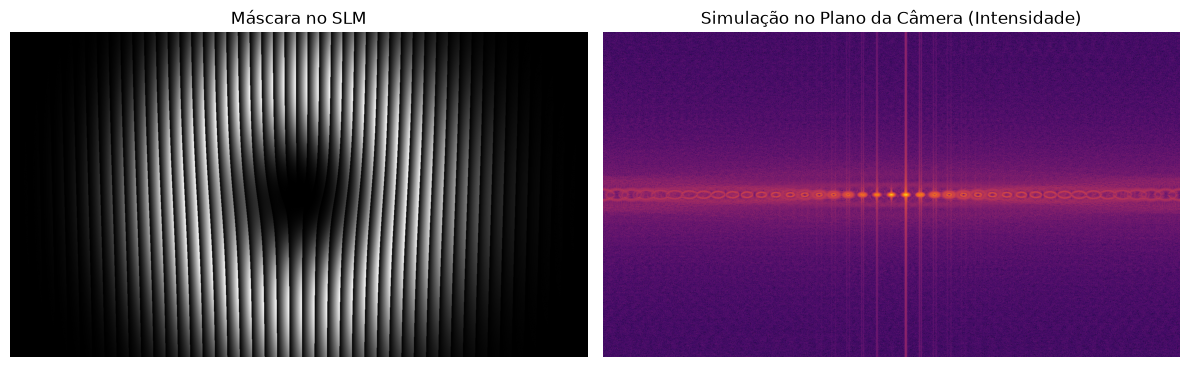

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

def simular_propagacao(caminho_imagem):
    # 1. Carregar a máscara (imagem do SLM) e converter para tons de cinza
    img = Image.open(caminho_imagem).convert('L')
    mascara_pixels = np.array(img)
    
    # 2. Mapear os pixels de [0, 255] para fase óptica de [0, 2*pi]
    fase_slm = (mascara_pixels / 255.0) * (2 * np.pi)
    
    # 3. Criar o campo elétrico complexo (simulando um laser plano incidindo no SLM)
    # A luz incidente tem amplitude uniforme (1) e a fase ditada pelo SLM: E = A * exp(i * fase)
    campo_incidente = np.ones_pattern = np.ones_like(fase_slm)
    campo_refletido = campo_incidente * np.exp(1j * fase_slm)
    
    # 4. Simular a lente/campo distante usando a Transformada de Fourier 2D
    campo_distante = np.fft.fft2(campo_refletido)
    campo_distante = np.fft.fftshift(campo_distante) # Centraliza a ordem zero no meio da imagem
    
    # 5. Calcular a intensidade da luz (o que a câmera captura é o quadrado da magnitude)
    intensidade = np.abs(campo_distante)**2
    
    # Aplicamos uma escala logarítmica para visualização, pois a ordem zero costuma 
    # ser extremamente mais brilhante que a primeira ordem no gráfico bruto.
    intensidade_log = np.log1p(intensidade)
    
    # 6. Plotar os resultados
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5))
    
    ax1.imshow(mascara_pixels, cmap='gray')
    ax1.set_title('Máscara no SLM')
    ax1.axis('off')
    
    ax2.imshow(intensidade_log, cmap='inferno')
    ax2.set_title('Simulação no Plano da Câmera (Intensidade)')
    ax2.axis('off')
    
    plt.tight_layout()
    plt.show()

# Execute a simulação com a sua imagem
simular_propagacao("/home/pedro/Dev/Playground/util/jupiter/phase_masks/masks_gen_pipeline/LG_p0_l3_amplitude_modificada.bmp")

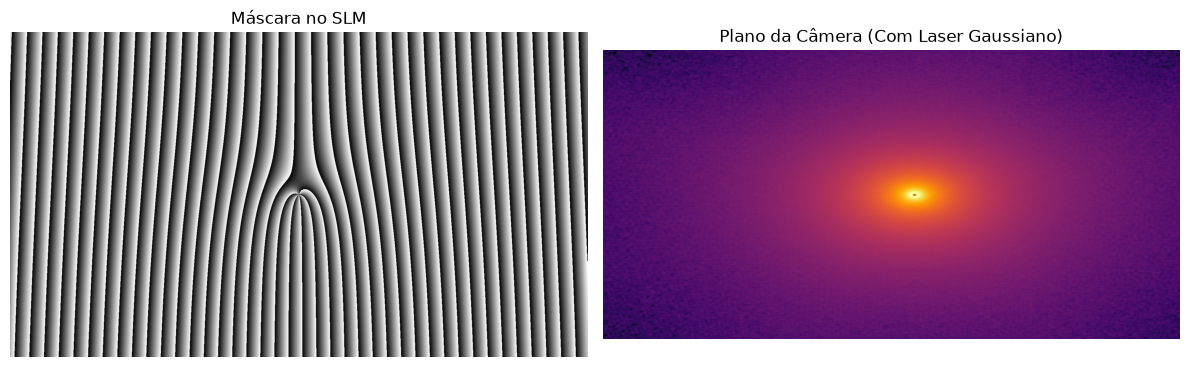

In [15]:
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

def simular_propagacao_corrigida(caminho_imagem):
    # 1. Carregar a máscara e converter para radianos
    img = Image.open(caminho_imagem).convert('L')
    mascara_pixels = np.array(img)
    fase_slm = (mascara_pixels / 255.0) * (2 * np.pi)
    
    # 2. Criar coordenadas para definir o centro da imagem
    altura, largura = fase_slm.shape
    y, x = np.indices((altura, largura))
    centro_y, centro_x = altura // 2, largura // 2
    
    # 3. Criar o perfil Gaussiano do laser incidente
    # w0 representa o raio do feixe. Ajustamos para ocupar cerca de um quarto do ecrã.
    w0 = min(altura, largura) / 4.0
    perfil_laser = np.exp(-((x - centro_x)**2 + (y - centro_y)**2) / (w0**2))
    
    # 4. Campo refletido agora leva em conta o perfil suave do laser
    campo_refletido = perfil_laser * np.exp(1j * fase_slm)
    
    # 5. Simular o campo distante (lente/FFT)
    campo_distante = np.fft.fft2(campo_refletido)
    campo_distante = np.fft.fftshift(campo_distante)
    
    # 6. Calcular intensidade e plotar
    intensidade = np.abs(campo_distante)**2
    
    # Adicionamos um pequeno recorte (crop) ao redor do centro para ver melhor as ordens difratadas
    margem = largura // 4
    intensidade_crop = intensidade[
        centro_y - margem//2 : centro_y + margem//2,
        centro_x - margem : centro_x + margem
    ]
    
    intensidade_log = np.log1p(intensidade_crop)
    
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5))
    
    ax1.imshow(mascara_pixels, cmap='gray')
    ax1.set_title('Máscara no SLM')
    ax1.axis('off')
    
    ax2.imshow(intensidade_log, cmap='inferno')
    ax2.set_title('Plano da Câmera (Com Laser Gaussiano)')
    ax2.axis('off')
    
    plt.tight_layout()
    plt.show()

# Teste com a sua imagem gerada
simular_propagacao_corrigida("/home/pedro/Dev/Playground/util/jupiter/phase_masks/masks_gen_pipeline/mascaras_oam/OAM_l-5_grating.bmp")

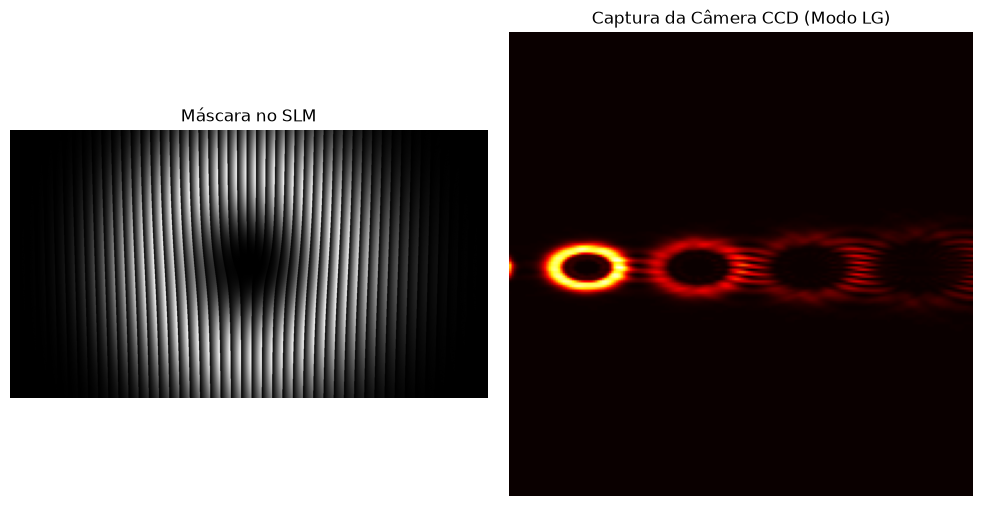

In [17]:
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

def simular_visao_ccd(caminho_imagem):
    # 1. Carregar a máscara e converter para radianos
    img = Image.open(caminho_imagem).convert('L')
    mascara_pixels = np.array(img)
    fase_slm = (mascara_pixels / 255.0) * (2 * np.pi)
    
    altura, largura = fase_slm.shape
    y, x = np.indices((altura, largura))
    centro_y, centro_x = altura // 2, largura // 2
    
    # 2. Perfil do Laser Incidente Gaussiano
    w0 = min(altura, largura) / 4.0
    perfil_laser = np.exp(-((x - centro_x)**2 + (y - centro_y)**2) / (w0**2))
    
    # 3. Propagação (Transformada de Fourier)
    campo_refletido = perfil_laser * np.exp(1j * fase_slm)
    campo_distante = np.fft.fftshift(np.fft.fft2(campo_refletido))
    intensidade = np.abs(campo_distante)**2
    
    # 4. SIMULAÇÃO DO POSICIONAMENTO DA CÂMERA CCD
    # Vamos apagar temporariamente a ordem zero (centro) para encontrar onde está o feixe lateral
    intensidade_busca = np.copy(intensidade)
    margem_bloqueio = largura // 10
    intensidade_busca[:, centro_x - margem_bloqueio : centro_x + margem_bloqueio] = 0
    
    # Encontra as coordenadas do pico mais brilhante restante (a 1ª ordem de difração)
    py, px = np.unravel_index(np.argmax(intensidade_busca), intensidade_busca.shape)
    
    # Tamanho do sensor da câmera CCD (zoom na 1ª ordem)
    zoom = 100 
    
    # Recorta a imagem ao redor do feixe OAM
    ccd_captura = intensidade[
        py - zoom : py + zoom,
        px - zoom : px + zoom
    ]
    
    # Normaliza a intensidade para 8-bits (0-255) como uma câmera real
    ccd_captura = ccd_captura / np.max(ccd_captura)
    
    # 5. Plotando o resultado
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 5))
    
    ax1.imshow(mascara_pixels, cmap='gray')
    ax1.set_title('Máscara no SLM')
    ax1.axis('off')
    
    # Usamos o cmap 'hot' ou 'magma' que imita o software de câmeras de perfil de feixe (beam profilers)
    ax2.imshow(ccd_captura, cmap='hot', vmin=0, vmax=1)
    ax2.set_title('Captura da Câmera CCD (Modo LG)')
    ax2.axis('off')
    
    plt.tight_layout()
    plt.show()

# Teste com a sua imagem atual
simular_visao_ccd("/home/pedro/Dev/Playground/util/jupiter/phase_masks/masks_gen_pipeline/LG_p0_l3_amplitude_modificada.bmp")

In [1]:
slm_sim_code = '''"""
slm_sim.py - simulador escalar SLM -> lente -> CCD (plano focal, Fraunhofer).

Modelo
------
- Laser gaussiano (amplitude exp(-r^2/w0^2)) incide no SLM de fase pixelado.
- SLM no plano focal frontal da lente  =>  CCD no plano focal traseiro enxerga
  a transformada de Fourier do campo, com coordenadas fisicas u = lambda*f*fx.
- Em vez de FFT + zero-padding, o campo e avaliado por DFT direta
  exatamente nos pixels do CCD (com sub-amostragem para integrar o pixel).
  Assim a amostragem do anel e a do sensor real, sem depender de padding.
- Inclui: quantizacao 8 bits do SLM (via gray -> fase), envelope sinc do pixel
  do SLM (fill factor), CCD com ruido de disparo, ruido de leitura,
  saturacao (full well) e ADC de N bits.
- Suporta tanto modos LG puros (anel) quanto a superposicao coerente de dois
  modos LG (ex.: +l e -l, gerando 2|l| petalas na saida).

Todas as unidades internas sao SI (metros, radianos).
"""
from __future__ import annotations

import argparse
from dataclasses import dataclass

import numpy as np
from scipy.ndimage import gaussian_filter


# --------------------------------------------------------------------------- #
# Parametros da bancada
# --------------------------------------------------------------------------- #
@dataclass
class Setup:
    wavelength: float = 532e-9      # m
    slm_pitch: float = 8e-6         # m   (pitch do pixel do SLM)
    slm_fill: float = 0.93          # fill factor (area ativa / area do pixel)
    phase_max: float = 2 * np.pi    # fase correspondente ao nivel de cinza 255
    w0: float = 2.16e-3             # m   raio do feixe no SLM (campo cai a 1/e)
    f: float = 0.300                # m   distancia focal da lente
    cam_pitch: float = 5.2e-6       # m   pixel do CCD
    cam_shape: tuple = (256, 256)   # (ny, nx) da regiao de interesse simulada
    sub: int = 2                    # sub-amostras por pixel do CCD (integracao)
    full_well: float = 20000.0      # eletrons
    read_noise: float = 10.0        # eletrons rms
    bits: int = 12                  # ADC
    exposure: float = 0.8           # pico = exposure * full_well (>1 satura)

    @property
    def lf(self) -> float:
        return self.wavelength * self.f


# --------------------------------------------------------------------------- #
# SLM
# --------------------------------------------------------------------------- #
def phase_from_gray(gray: np.ndarray, s: Setup, lut: np.ndarray | None = None):
    """Nivel de cinza (0..255) -> fase. `lut` (256 valores, rad) substitui o mapa linear."""
    g = np.asarray(gray)
    if lut is not None:
        return np.asarray(lut, dtype=np.float64)[g]
    return g.astype(np.float64) / 255.0 * s.phase_max


def slm_coords(shape, s: Setup):
    H, W = shape
    x = (np.arange(W) - (W - 1) / 2) * s.slm_pitch
    y = (np.arange(H) - (H - 1) / 2) * s.slm_pitch
    return x, y


def slm_field(gray, s: Setup, lut=None, beam_center=(0.0, 0.0)):
    """Campo complexo logo apos o SLM. Retorna (E, x, y)."""
    ph = phase_from_gray(gray, s, lut)
    x, y = slm_coords(ph.shape, s)
    cx, cy = beam_center
    A = np.exp(-((x[None, :] - cx) ** 2 + (y[:, None] - cy) ** 2) / s.w0 ** 2)
    return A * np.exp(1j * ph), x, y


# --------------------------------------------------------------------------- #
# Propagacao ate o plano focal (DFT direta na grade desejada)
# --------------------------------------------------------------------------- #
def focal_field(E, x, y, u, v, s: Setup):
    """
    E(u,v) = sum E(x,y) exp(-i 2pi (x u + y v)/(lambda f))  x  envelope do pixel.
    u, v: coordenadas (m) no plano do CCD. Retorna matriz (len(v), len(u)).
    """
    k = 2 * np.pi / s.lf
    Ax = np.exp(-1j * k * np.outer(x, u)).astype(np.complex64)   # (W, nu)
    Ay = np.exp(-1j * k * np.outer(v, y)).astype(np.complex64)   # (nv, H)
    F = Ay @ (E.astype(np.complex64) @ Ax)
    a = s.slm_pitch * np.sqrt(s.slm_fill)                        # lado do pixel ativo
    F *= np.sinc(a * v / s.lf)[:, None] * np.sinc(a * u / s.lf)[None, :]
    return F


def cam_axes(center, n, pitch, sub):
    step = pitch / sub
    return center + (np.arange(n * sub) - (n * sub - 1) / 2) * step


def bin_pixels(I, ny, nx, sub):
    return I.reshape(ny, sub, nx, sub).mean(axis=(1, 3))


def roi_intensity(E, x, y, center, s: Setup, pitch=None, shape=None, sub=None):
    pitch = s.cam_pitch if pitch is None else pitch
    ny, nx = s.cam_shape if shape is None else shape
    sub = s.sub if sub is None else sub
    u = cam_axes(center[0], nx, pitch, sub)
    v = cam_axes(center[1], ny, pitch, sub)
    F = focal_field(E, x, y, u, v, s)
    I = np.abs(F).astype(np.float64) ** 2
    return F, I, bin_pixels(I, ny, nx, sub), u, v


def find_first_order(E, s: Setup):
    """Posicao (u, v) em metros do pico mais forte fora da ordem zero (busca grossa por FFT)."""
    H, W = E.shape
    I = np.abs(np.fft.fftshift(np.fft.fft2(E))) ** 2
    du = s.lf / (W * s.slm_pitch)
    dv = s.lf / (H * s.slm_pitch)
    u = (np.arange(W) - W // 2) * du
    v = (np.arange(H) - H // 2) * dv
    U, V = np.meshgrid(u, v)
    block = 6 * s.lf / (np.pi * s.w0)          # ~6x o raio da mancha da ordem zero
    I[np.hypot(U, V) < block] = 0
    I = gaussian_filter(I, 1.5)
    iy, ix = np.unravel_index(np.argmax(I), I.shape)
    return float(u[ix]), float(v[iy])


def _centroid(I, u, v):
    # I esta em grade sub-amostrada com os mesmos u (colunas) e v (linhas)
    tot = I.sum()
    return float((I.sum(0) * u).sum() / tot), float((I.sum(1) * v).sum() / tot)


# --------------------------------------------------------------------------- #
# CCD
# --------------------------------------------------------------------------- #
def ccd_capture(I, s: Setup, rng=None, noise=True, ref=None):
    """`ref`: intensidade que corresponde a `exposure` (padrao: pico da ROI inteira).
    Pixels mais brilhantes que `ref/exposure` saturam, como numa camera real."""
    rng = np.random.default_rng() if rng is None else rng
    ref = I.max() if ref is None else ref
    e = I / ref * s.exposure * s.full_well              # eletrons esperados
    if noise:
        e = rng.poisson(e).astype(np.float64) + rng.normal(0, s.read_noise, e.shape)
    e = np.clip(e, 0, s.full_well)                      # saturacao
    dtype = np.uint16 if s.bits > 8 else np.uint8
    return np.round(e / s.full_well * (2 ** s.bits - 1)).astype(dtype)


# --------------------------------------------------------------------------- #
# Pipeline completo
# --------------------------------------------------------------------------- #
def simulate(gray, s: Setup | None = None, center="auto", lut=None,
             noise=True, seed=0, beam_center=(0.0, 0.0), ref_radius=None):
    """
    gray: matriz uint8 (H, W) com a mascara enviada ao SLM.
    center: "auto" (acha a 1a ordem e recentra no centroide) ou (u, v) em metros.
    ref_radius: raio (m) ao redor de `center` usado como referencia de exposicao
        (o pico dentro dele vale `exposure`; o que for mais brilhante, como a ordem
        zero, satura). Padrao: com center="auto" usa a janela do feixe; com center
        manual usa o pico da ROI inteira.
    """
    s = s or Setup()
    E, x, y = slm_field(gray, s, lut, beam_center)
    half = 0.5 * min(s.cam_shape) * s.cam_pitch

    if center == "auto":
        c = list(find_first_order(E, s))
        # Janela de busca: nunca chega na ordem zero (distancia d da origem), senao o
        # centroide e arrastado para ela quando o periodo da rede e grande.
        R = min(0.45 * float(np.hypot(*c)), half)
        for _ in range(3):                              # refina no centroide do anel/petalas
            _, Isub, _, u, v = roi_intensity(E, x, y, c, s, sub=1)
            U, V = np.meshgrid(u, v)
            win = np.hypot(U - c[0], V - c[1]) < R
            Isub = np.where(win & (Isub > 0.02 * Isub[win].max()), Isub, 0.0)
            c = list(_centroid(Isub, u, v))
        center = tuple(c)
        if ref_radius is None:
            ref_radius = R

    F, Isub, I, u, v = roi_intensity(E, x, y, center, s)
    ref = None
    if ref_radius is not None:
        ny, nx = I.shape
        ub = cam_axes(center[0], nx, s.cam_pitch, 1)
        vb = cam_axes(center[1], ny, s.cam_pitch, 1)
        UB, VB = np.meshgrid(ub, vb)
        ref = I[np.hypot(UB - center[0], VB - center[1]) < ref_radius].max()
    counts = ccd_capture(I, s, np.random.default_rng(seed), noise, ref=ref)
    return dict(center=center, E=F, I_sub=Isub, I=I, counts=counts, u=u, v=v,
                setup=s, E_slm=E, x=x, y=y)


def overview(res, bin_factor=8):
    """Sensor inteiro com binning (mostra todas as ordens). Retorna intensidade (ny, nx)."""
    s = res["setup"]
    ny = 1024 // bin_factor
    nx = 1280 // bin_factor
    _, _, I, _, _ = roi_intensity(res["E_slm"], res["x"], res["y"], (0.0, 0.0), s,
                                  pitch=s.cam_pitch * bin_factor, shape=(ny, nx), sub=2)
    return I


# --------------------------------------------------------------------------- #
# Gerador de mascara de teste: LG por Bolduc et al. (anel ou petalas)
# --------------------------------------------------------------------------- #
def _modulation_depth(A):
    """M(A) tal que a 1a ordem de um blaze de profundidade M tem amplitude A: sinc(1-M) = A."""
    xs = np.linspace(0, 1, 4001)
    sinc = np.sinc(xs)                                  # decrescente de 1 a 0
    inv = np.interp(np.clip(A, 0, 1), sinc[::-1], xs[::-1])
    return 1.0 - inv


def _lg_radial(r, l, w_lg):
    """Envelope radial LG_0^|l| normalizado para ter pico igual a 1."""
    lp = abs(l)
    if lp == 0:
        return np.exp(-r ** 2 / w_lg ** 2)
    r_pk = w_lg * np.sqrt(lp / 2)
    return (r / r_pk) ** lp * np.exp(-r ** 2 / w_lg ** 2 + lp / 2)


def bolduc_mask(shape=(1080, 1920), s: Setup | None = None, l=3, w_lg=1.0e-3,
                period_px=24, petals=False, l2: int | None = None, delta_deg=0.0):
    """
    Mascara uint8 que gera LG_0^l (ou superposicao coerente) na 1a ordem.
    - Se petals=True (ou l2 for especificado): soma LG_0^l + exp(i*delta) * LG_0^l2
      (padrao l2 = -l, gerando 2|l| petalas simetricas).
    """
    s = s or Setup()
    x, y = slm_coords(shape, s)
    X, Y = np.meshgrid(x, y)
    r = np.hypot(X, Y)
    th = np.arctan2(Y, X)

    E1 = _lg_radial(r, l, w_lg) * np.exp(1j * l * th)

    if petals or (l2 is not None):
        l_sec = -l if l2 is None else l2
        delta = np.deg2rad(delta_deg)
        E2 = _lg_radial(r, l_sec, w_lg) * np.exp(1j * (l_sec * th + delta))
        E_target = E1 + E2
        peak = np.abs(E_target).max()
        if peak > 0:
            E_target = E_target / peak
    else:
        E_target = E1

    A = np.clip(np.abs(E_target), 0, 1)
    Phi_field = np.angle(E_target)

    M = _modulation_depth(A)
    Phi = Phi_field + 2 * np.pi * X / (period_px * s.slm_pitch)
    # Dente de serra CENTRADO em zero (-pi..pi) multiplicado por M(A): so assim o coeficiente
    # da 1a ordem e real, sinc(M-1) = A, sem fase espuria exp(i*pi*M(A)) variando no feixe.
    saw = np.mod(Phi + np.pi, 2 * np.pi) - np.pi
    ph = M * saw + np.pi
    return np.round(ph / s.phase_max * 255).astype(np.uint8)


# --------------------------------------------------------------------------- #
# Plot / CLI
# --------------------------------------------------------------------------- #
def plot_result(gray, res, out=None, show=True, title_suffix=""):
    import matplotlib
    if not show:
        matplotlib.use("Agg")
    import matplotlib.pyplot as plt

    s = res["setup"]
    ov = overview(res)
    ny, nx = res["counts"].shape
    ext = np.array([-nx / 2, nx / 2, ny / 2, -ny / 2]) * s.cam_pitch * 1e3   # mm
    cu, cv = res["center"]
    ext_roi = [cu * 1e3 + ext[0], cu * 1e3 + ext[1], cv * 1e3 + ext[2], cv * 1e3 + ext[3]]
    ext_ov = np.array([-640, 640, 512, -512]) * s.cam_pitch * 1e3

    fig, ax = plt.subplots(1, 3, figsize=(16, 5))
    ax[0].imshow(gray, cmap="gray", vmin=0, vmax=255)
    ax[0].set_title(f"Mascara no SLM ({gray.shape[1]}x{gray.shape[0]}){title_suffix}")
    ax[0].axis("off")

    ax[1].imshow(np.log10(ov / ov.max() + 1e-6), cmap="magma", extent=ext_ov, vmin=-5, vmax=0)
    ax[1].add_patch(plt.Rectangle((ext_roi[0], ext_roi[3]), ext_roi[1] - ext_roi[0],
                                  ext_roi[2] - ext_roi[3], fill=False, ec="cyan", lw=1))
    ax[1].set_title("Sensor inteiro (log, binning 8x)")
    ax[1].set_xlabel("u (mm)"); ax[1].set_ylabel("v (mm)")

    ax[2].imshow(res["counts"], cmap="inferno", extent=ext_roi)
    ax[2].set_title(f"CCD simulado, ROI {nx}x{ny} px (linear, {s.bits} bits)")
    ax[2].set_xlabel("u (mm)"); ax[2].set_ylabel("v (mm)")

    fig.tight_layout()
    if out:
        fig.savefig(out, dpi=140)
    if show:
        plt.show()
    plt.close(fig)


def main():
    p = argparse.ArgumentParser(description="Simulador SLM -> lente -> CCD")
    p.add_argument("--mask", help="BMP/PNG em tons de cinza (0..255 -> 0..phase_max)")
    p.add_argument("--demo", action="store_true", help="gera mascara LG de teste (Bolduc)")
    p.add_argument("--l", type=int, default=3, help="carga topologica principal l")
    p.add_argument("--petals", action="store_true", help="soma coerente l e -l (gera 2|l| petalas)")
    p.add_argument("--l2", type=int, default=None, help="segunda carga l2 para superposicao arbitraria")
    p.add_argument("--delta-deg", type=float, default=0.0, help="fase relativa em graus entre os modos")
    p.add_argument("--w-lg-mm", type=float, default=1.0)
    p.add_argument("--period-px", type=float, default=24)
    p.add_argument("--lambda-nm", type=float, default=633)
    p.add_argument("--pitch-um", type=float, default=8.0)
    p.add_argument("--f-mm", type=float, default=300.0)
    p.add_argument("--w0-mm", type=float, default=2.16)
    p.add_argument("--cam-pitch-um", type=float, default=5.2)
    p.add_argument("--roi", type=int, default=256)
    p.add_argument("--bits", type=int, default=12)
    p.add_argument("--exposure", type=float, default=0.8)
    p.add_argument("--phase-max-2pi", type=float, default=1.0,
                   help="fase em gray=255 em unidades de 2pi (ex.: 0.9 se o SLM nao chega a 2pi)")
    p.add_argument("--center-mm", type=float, nargs=2, default=None,
                   help="u v do centro do ROI em mm (padrao: acha a 1a ordem)")
    p.add_argument("--no-noise", action="store_true")
    p.add_argument("--out", default="sim.png")
    p.add_argument("--no-show", action="store_true")
    a = p.parse_args()

    s = Setup(wavelength=a.lambda_nm * 1e-9, slm_pitch=a.pitch_um * 1e-6, f=a.f_mm * 1e-3,
              w0=a.w0_mm * 1e-3, cam_pitch=a.cam_pitch_um * 1e-6, cam_shape=(a.roi, a.roi),
              bits=a.bits, exposure=a.exposure, phase_max=2 * np.pi * a.phase_max_2pi)

    if a.demo:
        gray = bolduc_mask((1080, 1920), s, a.l, a.w_lg_mm * 1e-3, a.period_px,
                           petals=a.petals, l2=a.l2, delta_deg=a.delta_deg)
    elif a.mask:
        from PIL import Image
        gray = np.array(Image.open(a.mask).convert("L"))
    else:
        p.error("use --mask arquivo.bmp ou --demo")

    center = "auto" if a.center_mm is None else (a.center_mm[0] * 1e-3, a.center_mm[1] * 1e-3)
    res = simulate(gray, s, center=center, noise=not a.no_noise)
    print(f"centro do ROI: u={res['center'][0]*1e3:.3f} mm, v={res['center'][1]*1e3:.3f} mm")
    plot_result(gray, res, out=a.out, show=not a.no_show)


if __name__ == "__main__":
    main()
'''

with open("slm_sim.py", "w", encoding="utf-8") as f:
    f.write(slm_sim_code)

# Run actual simulations using the newly saved module and create output plots + masks
import slm_sim
from PIL import Image
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
import numpy as np

s = slm_sim.Setup(wavelength=633e-9, slm_pitch=8e-6, f=0.300, w0=2.16e-3, cam_pitch=5.2e-6, cam_shape=(256, 256))

# 1. Simulate l = 1 and l = -1 superposition (2 petals)
mask_l1_petals = slm_sim.bolduc_mask((1080, 1920), s, l=1, w_lg=1.0e-3, period_px=24, petals=True)
Image.fromarray(mask_l1_petals).save("mascara_slm_l1_menos1_petalas.png")
res_l1_petals = slm_sim.simulate(mask_l1_petals, s, center="auto", noise=True)
slm_sim.plot_result(mask_l1_petals, res_l1_petals, out="simulacao_l1_menos1_2petalas.png", show=False, title_suffix=" [l=+1 e -1]")

# 2. Simulate l = 3 and l = -3 superposition (6 petals)
mask_l3_petals = slm_sim.bolduc_mask((1080, 1920), s, l=3, w_lg=1.0e-3, period_px=24, petals=True)
Image.fromarray(mask_l3_petals).save("mascara_slm_l3_menos3_petalas.png")
res_l3_petals = slm_sim.simulate(mask_l3_petals, s, center="auto", noise=True)
slm_sim.plot_result(mask_l3_petals, res_l3_petals, out="simulacao_l3_menos3_6petalas.png", show=False, title_suffix=" [l=+3 e -3]")

# 3. Create a comparative panel (l=1 Ring vs l=+-1 Petals vs l=+-3 Petals)
mask_l1_ring = slm_sim.bolduc_mask((1080, 1920), s, l=1, w_lg=1.0e-3, period_px=24, petals=False)
res_l1_ring = slm_sim.simulate(mask_l1_ring, s, center="auto", noise=True)

fig, axes = plt.subplots(2, 3, figsize=(15, 9.5))
cases = [
    ("Garfo Unico (l = +1) -> Anel", mask_l1_ring, res_l1_ring),
    ("Superposicao (l = +1 e -1) -> 2 Petalas", mask_l1_petals, res_l1_petals),
    ("Superposicao (l = +3 e -3) -> 6 Petalas", mask_l3_petals, res_l3_petals),
]

for col, (title, m, r) in enumerate(cases):
    # Crop central 250x250 px of the SLM mask so the fork / phase shift lines are clearly visible
    H, W = m.shape
    cy, cx = H // 2, W // 2
    crop = m[cy - 125:cy + 125, cx - 125:cx + 125]
    axes[0, col].imshow(crop, cmap="gray", vmin=0, vmax=255)
    axes[0, col].set_title(f"Zoom Central SLM (250x250 px)\n{title}", fontsize=11, fontweight="bold")
    axes[0, col].axis("off")

    ny, nx = r["counts"].shape
    cu, cv = r["center"]
    ext = np.array([-nx / 2, nx / 2, ny / 2, -ny / 2]) * s.cam_pitch * 1e3
    ext_roi = [cu * 1e3 + ext[0], cu * 1e3 + ext[1], cv * 1e3 + ext[2], cv * 1e3 + ext[3]]
    im = axes[1, col].imshow(r["counts"], cmap="inferno", extent=ext_roi)
    axes[1, col].set_title(f"CCD ROI 256x256 px (centro u={cu*1e3:.2f} mm)", fontsize=11)
    axes[1, col].set_xlabel("u (mm)")
    axes[1, col].set_ylabel("v (mm)")
    plt.colorbar(im, ax=axes[1, col], fraction=0.046, pad=0.04, label="Contagens (12 bits)")

fig.suptitle("Comparacao Direta: Garfo Unico vs. Soma de Garfos Simetricamente Opostos (+l e -l)", fontsize=14, fontweight="bold")
fig.tight_layout()
fig.savefig("comparacao_garfos_e_petalas.png", dpi=150)
plt.close(fig)

print("Done! Centers:", res_l1_petals["center"], res_l3_petals["center"])

Done! Centers: (0.0009889937718904, -3.204573486574748e-13) (0.0009889539349675384, 6.381600764224963e-11)
